In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error, r2_score

In [3]:
df = pd.read_csv("datasets/mpg.csv")[['displacement', 'mpg']].dropna()
print(df.head())

   displacement   mpg
0         307.0  18.0
1         350.0  15.0
2         318.0  18.0
3         304.0  16.0
4         302.0  17.0


In [4]:
x, y = df[['displacement']], df[['mpg']]
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

In [5]:
x_range = pd.DataFrame(np.linspace(x.min().iloc[0], x.max().iloc[0], 300), columns=x.columns)

Degree: 1 -> MSE: 18.102543998358946 R2 score: 0.6633114869465596
Degree: 2 -> MSE: 15.107353561080766 R2 score: 0.7190189176110282
Degree: 3 -> MSE: 16.369649051540453 R2 score: 0.6955415327884606
Degree: 4 -> MSE: 18.3987903102031 R2 score: 0.657801613293364


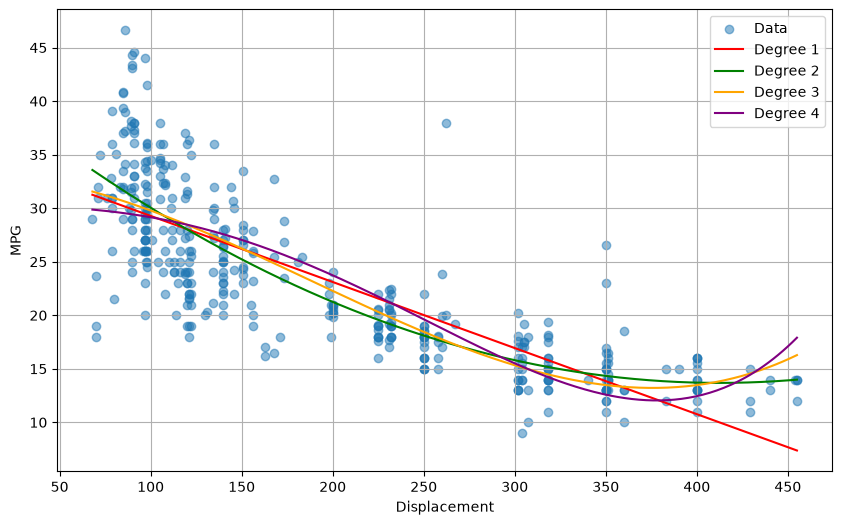

In [6]:
plt.figure(figsize=(10, 6))
plt.scatter(x, y, alpha=0.5, label='Data')
for deg, color in zip([1, 2, 3, 4], ['red', 'green', 'orange', 'purple']):
    model = make_pipeline(PolynomialFeatures(deg), LinearRegression())
    model.fit(x_train, y_train)
    y_pred = model.predict(x_test)
    print(f"Degree: {deg} -> MSE: {mean_squared_error(y_test, y_pred)} R2 score: {r2_score(y_test, y_pred)}")
    plt.plot(x_range, model.predict(x_range), color=color, label=f'Degree {deg}')
plt.xlabel("Displacement")
plt.ylabel("MPG")
plt.legend()
plt.grid()
plt.show()